<a href="https://colab.research.google.com/github/nizarbanu/RNN_3-RNN-for-Time-Series-Prediction/blob/main/RNN_Learner_Notebook_3_RNN_for_Time_Series_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RNN Learner Notebook 3 — RNN for Time-Series Prediction

### From Sequential Representation to Prediction

This notebook completes the RNN learning sequence:

- **Notebook 1:** Understand RNNs and hidden-state representation.
- **Notebook 2:** Understand sequence mappings, BPTT, and gradient challenges.
- **Notebook 3:** Build, train, evaluate, and experiment with an RNN.

We will use a small **synthetic time-series forecasting task**. The model receives a sequence of past values and predicts the next value. No external dataset download is required.

> **Learning flow:** Concept → Prepare Data → Build Model → Train → Evaluate → Experiment → Reflect

## 1. Learning Objectives

By the end of this notebook, you should be able to:

1. Represent sequential data in the shape expected by an RNN.
2. Prepare input windows and next-step targets.
3. Build a simple RNN using TensorFlow/Keras.
4. Explain the role of the recurrent and output layers.
5. Train the model and interpret training/validation loss.
6. Compare predictions with actual values.
7. Experiment with sequence length and the number of hidden units.
8. Connect the learned hidden-state representation with sequential prediction.

## 2. Recall: What Does an RNN Learn?

An RNN processes a sequence one time step at a time. Its hidden state is updated using the current input and the previous hidden state.

For this task:

**Past observations → RNN → Hidden-state representation → Dense layer → Next-value prediction**

The model learns patterns and parameters from training examples to predict the next value, rather than following explicitly programmed rules.

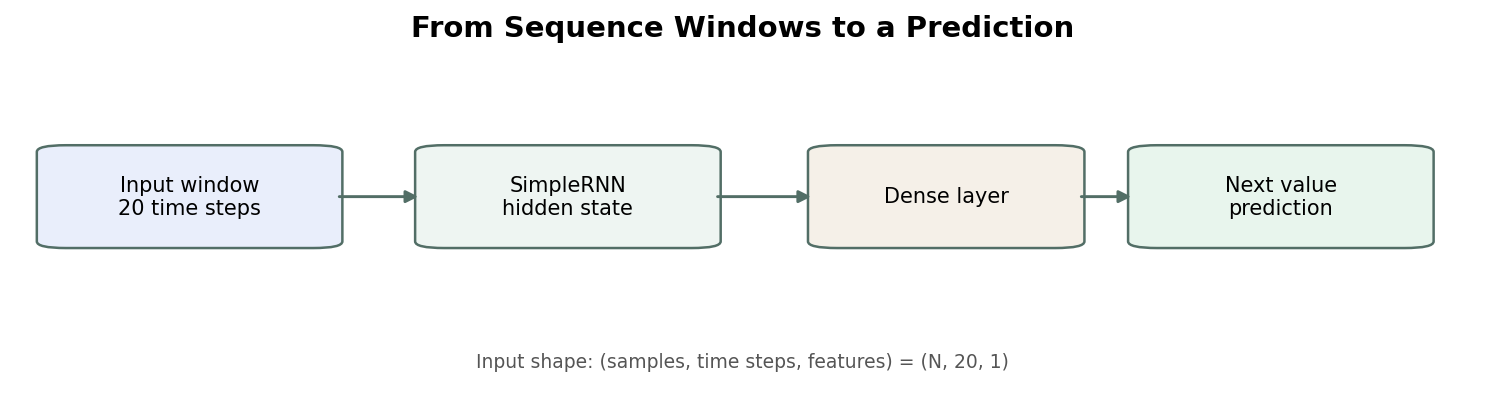

## 3. The Task — Predict the Next Value

Suppose a time series contains values:

**x₁, x₂, x₃, …, x₂₀, x₂₁, …**

We will give the model the first 20 values and ask it to predict the next value.

- **Input window:** x₁ to x₂₀
- **Target:** x₂₁

Then the window slides forward by one step:

- **Next input window:** x₂ to x₂₁
- **Next target:** x₂₂

This is a **many-to-one** setup: a sequence of inputs produces one prediction.

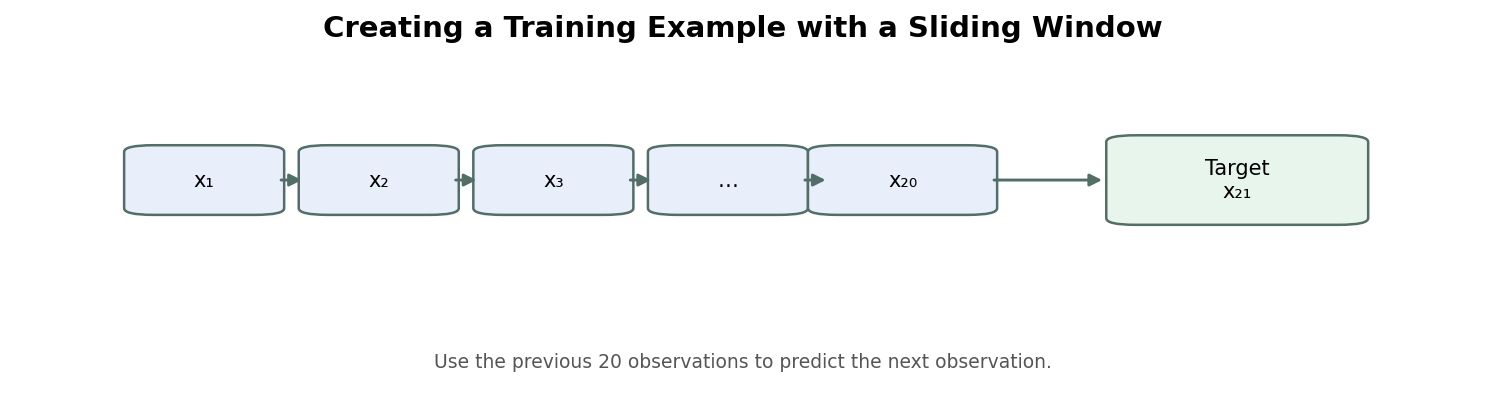

## 4. Prepare the Environment

We use NumPy for data preparation, Matplotlib for visualization, and TensorFlow/Keras to build the RNN.

**In Google Colab:** TensorFlow is usually available by default. If the import fails in another environment, install a compatible TensorFlow version before continuing.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully.")

TensorFlow version: 2.21.0
Libraries imported successfully.


## 5. Generate a Synthetic Sequential Dataset

Each series combines sine-wave patterns with different amplitudes, frequencies, and phases. This creates sequential patterns without downloading a dataset.

We will generate multiple series, then use sliding windows to create input-target pairs.

In [15]:
def generate_series(n_series=500, length=50, seed=42):
    rng = np.random.default_rng(seed)
    all_series = []

    for _ in range(n_series):
        amplitude_1 = rng.uniform(0.6, 1.4)
        amplitude_2 = rng.uniform(0.1, 0.5)
        frequency_1 = rng.uniform(0.04, 0.10)
        frequency_2 = rng.uniform(0.10, 0.18)
        phase_1 = rng.uniform(0, 2 * np.pi)
        phase_2 = rng.uniform(0, 2 * np.pi)
        time = np.arange(length)

        values = (
            amplitude_1 * np.sin(frequency_1 * time + phase_1)
            + amplitude_2 * np.sin(frequency_2 * time + phase_2)
        )
        values += rng.normal(0, 0.03, size=length)
        all_series.append(values)

    return np.asarray(all_series, dtype=np.float32)

series = generate_series()
print("Dataset shape:", series.shape)
print("Number of series:", series.shape[0])
print("Time steps per series:", series.shape[1])

Dataset shape: (500, 50)
Number of series: 500
Time steps per series: 50


### Observe the Data

Each row is one time series. Each column is one time step.

The values are synthetic, so the task is intended to teach the modelling workflow—not to represent a real-world forecasting benchmark.

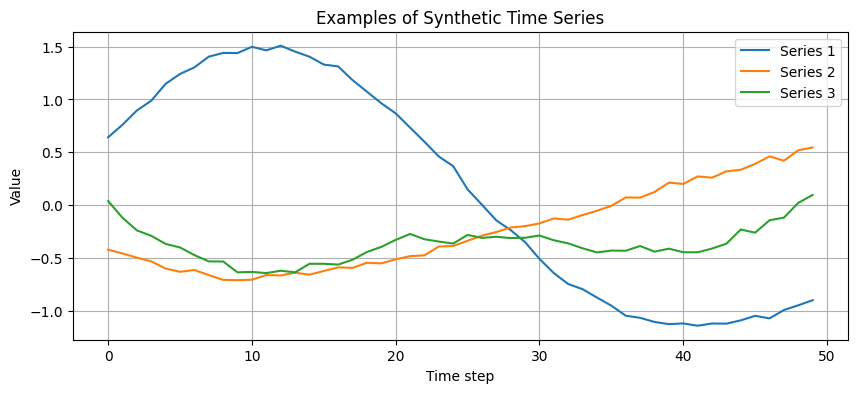

In [16]:
plt.figure(figsize=(10, 4))
for i in range(3):
    plt.plot(series[i], label=f"Series {i + 1}")
plt.xlabel("Time step")
plt.ylabel("Value")
plt.title("Examples of Synthetic Time Series")
plt.legend()
plt.grid(True)
plt.show()

## 6. Create Sliding Windows

For a window length of 20, each example contains 20 consecutive values and the target is the next value.

The required input shape for a Keras RNN is:

**(number of samples, time steps, features)**

Here, each time step has one feature: the observed value.

In [17]:
def make_windows(data, window_size=20):
    X, y = [], []

    for one_series in data:
        for start in range(len(one_series) - window_size):
            end = start + window_size
            X.append(one_series[start:end])
            y.append(one_series[end])

    X = np.asarray(X, dtype=np.float32)[..., np.newaxis]
    y = np.asarray(y, dtype=np.float32)
    return X, y

WINDOW_SIZE = 20
X, y = make_windows(series, window_size=WINDOW_SIZE)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("One input sample shape:", X[0].shape)
print("One target value:", round(float(y[0]), 4))

X shape: (15000, 20, 1)
y shape: (15000,)
One input sample shape: (20, 1)
One target value: 0.8685


### Check the Shape

With 500 series, 50 time steps per series, and a window size of 20, each series contributes 30 examples.

Expected shapes:

- **X:** `(15000, 20, 1)`
- **y:** `(15000,)`

The final dimension of `X` is 1 because each time step contains one observed value.

## 7. Split into Training and Test Sets

We shuffle the generated windows before splitting because the series were independently generated. The test set is held out from model fitting and used to evaluate predictions.

In a real forecasting project, the split strategy must reflect the deployment setting. For example, forecasting future periods from the same series often requires a chronological split.

In [18]:
indices = np.random.default_rng(42).permutation(len(X))
split_at = int(0.8 * len(indices))

train_indices = indices[:split_at]
test_indices = indices[split_at:]

X_train, y_train = X[train_indices], y[train_indices]
X_test, y_test = X[test_indices], y[test_indices]

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Training input shape:", X_train.shape)
print("Test input shape:", X_test.shape)

Training samples: 12000
Test samples: 3000
Training input shape: (12000, 20, 1)
Test input shape: (3000, 20, 1)


## 8. Build the RNN Model

We use a `SimpleRNN` layer with 32 units, followed by a Dense layer with one output.

- **SimpleRNN:** processes the sequence and produces a final hidden-state representation.
- **Dense(1):** maps that representation to one predicted numerical value.
- **Mean Squared Error (MSE):** measures the squared difference between predictions and targets.
- **Adam:** updates the model parameters during training.

This is a regression task, so we do not use a softmax output.

In [19]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW_SIZE, 1), name="sequence_input"),
    tf.keras.layers.SimpleRNN(32, activation="tanh", name="rnn"),
    tf.keras.layers.Dense(1, name="next_value")
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rnn (SimpleRNN)                 │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_value (Dense)              │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

### Think Before Training

1. Why is the input shape `(20, 1)` rather than `(20,)`?
2. Why does the final Dense layer have one unit?
3. Why is `softmax` not suitable for this regression output?

## 9. Train the Model

During training, the model repeatedly:

1. processes an input sequence,
2. predicts the next value,
3. calculates the loss,
4. updates its parameters using backpropagation through the unrolled recurrent computation.

We use a small number of epochs to keep the exercise manageable. Results can vary slightly across TensorFlow versions and hardware.

In [13]:
history = model.fit(
    X_train,
    y_train,
    epochs=8,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0019 - mae: 0.0346 - val_loss: 0.0019 - val_mae: 0.0343
Epoch 2/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0019 - mae: 0.0345 - val_loss: 0.0019 - val_mae: 0.0342
Epoch 3/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - mae: 0.0344 - val_loss: 0.0019 - val_mae: 0.0341
Epoch 4/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - mae: 0.0344 - val_loss: 0.0019 - val_mae: 0.0341
Epoch 5/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - mae: 0.0343 - val_loss: 0.0019 - val_mae: 0.0340
Epoch 6/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - mae: 0.0343 - val_loss: 0.0019 - val_mae: 0.0340
Epoch 7/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - mae: 0.0342 - val_loss: 0.0019 - val_mae: 0.0340
Epoch 8/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - mae: 0.0342 - val_loss: 0.0019 - val_mae: 0.0339


## 10. Observe the Training Process

Training loss measures error on the training subset. Validation loss measures error on the validation subset that is not used to update the parameters during each epoch.

A decreasing loss is often a useful sign, but it does not by itself prove that a model will generalize well.

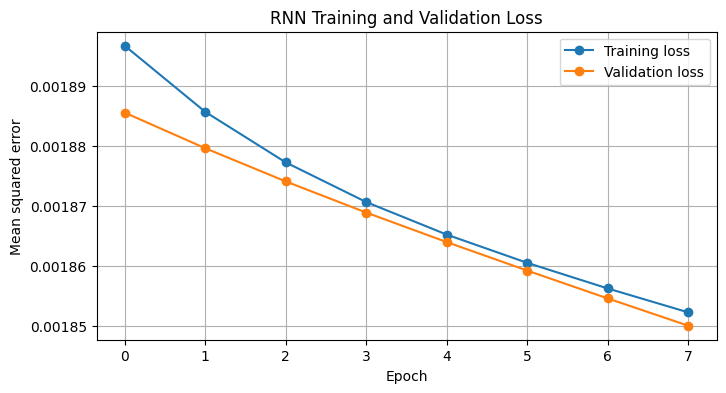

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("RNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 11. Evaluate on the Test Set

The test set gives an estimate of how well the trained model predicts examples that were not used for fitting.

We report **MSE** and **MAE**:

- **MSE:** average squared prediction error.
- **MAE:** average absolute prediction error.

Lower values indicate smaller errors for this dataset, but these metrics should be interpreted in the context of the target scale and task.

In [21]:
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)
print(f"Test MSE: {test_loss:.4f}")
print(f"Test MAE: {test_mae:.4f}")

Test MSE: 0.6285
Test MAE: 0.6913


## 12. Compare Predictions with Actual Values

We will compare the model's predictions with actual target values for a small sample from the test set.

Actual values : [-1.339 -0.058 -0.133  0.526  0.107 -0.392 -0.407  0.361 -0.461 -0.696
  1.071  1.028]
Predicted     : [ 0.094 -0.007  0.033 -0.025  0.067 -0.027 -0.037 -0.169  0.147  0.029
  0.069 -0.144]


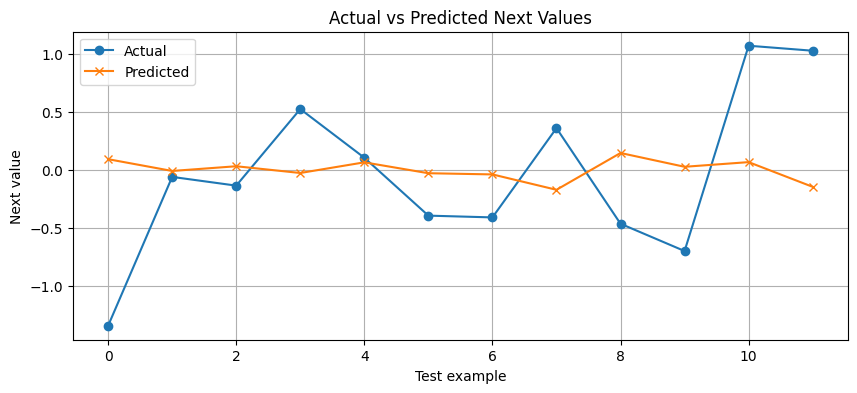

In [22]:
n_show = 12
predictions = model.predict(X_test[:n_show], verbose=0).reshape(-1)

print("Actual values :", np.round(y_test[:n_show], 3))
print("Predicted     :", np.round(predictions, 3))

plt.figure(figsize=(10, 4))
positions = np.arange(n_show)
plt.plot(positions, y_test[:n_show], marker="o", label="Actual")
plt.plot(positions, predictions, marker="x", label="Predicted")
plt.xlabel("Test example")
plt.ylabel("Next value")
plt.title("Actual vs Predicted Next Values")
plt.legend()
plt.grid(True)
plt.show()

### Interpret the Result

Think:

- Are predictions close to the actual values?
- Are some predictions less accurate than others?
- What might happen if the input sequence becomes longer?
- Would the same model work equally well on every type of time series?

Do not expect every prediction to match the target exactly.

## 13. Make One Prediction Manually

Take one input window from the test set. Its shape is `(20, 1)`. The model expects a batch dimension as well, so we add one to obtain `(1, 20, 1)`.

In [23]:
sample_window = X_test[0]
sample_batch = sample_window[np.newaxis, ...]

one_prediction = model.predict(sample_batch, verbose=0)[0, 0]

print("Input window shape:", sample_window.shape)
print("Model input shape:", sample_batch.shape)
print(f"Predicted next value: {one_prediction:.4f}")
print(f"Actual next value:    {y_test[0]:.4f}")

Input window shape: (20, 1)
Model input shape: (1, 20, 1)
Predicted next value: 0.0941
Actual next value:    -1.3391


## 14. Experiment 1 — Change the Number of Hidden Units

The number of RNN units affects the size of the hidden-state representation and the number of trainable parameters.

Try changing the number of units from 32 to 16 or 64. Keep the data split and training settings unchanged so that your comparison is easier to interpret.

**Before running a new experiment, record your expected result.**

In [24]:
# Experiment template: build a smaller RNN.
# Change 16 to 32 or 64 and compare the results.

experiment_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW_SIZE, 1)),
    tf.keras.layers.SimpleRNN(16, activation="tanh"),
    tf.keras.layers.Dense(1)
])

experiment_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

experiment_history = experiment_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=0
)

experiment_mse, experiment_mae = experiment_model.evaluate(X_test, y_test, verbose=0)
print(f"Experiment test MSE: {experiment_mse:.4f}")
print(f"Experiment test MAE: {experiment_mae:.4f}")

Experiment test MSE: 0.0026
Experiment test MAE: 0.0404


### Record Your Observation

| Model | Number of units | Epochs | Test MSE | Test MAE |
|---|---:|---:|---:|---:|
| Main model | 32 | 8 | Record output | Record output |
| Experiment | 16 (or your choice) | 5 | Record output | Record output |

The comparison is not perfectly controlled because the epoch counts differ. For a fair comparison, run both models for the same number of epochs and use the same data split.

## 15. Experiment 2 — Change the Sequence Length

The sequence length determines how many past observations are provided to the model.

- A shorter window provides less historical context.
- A longer window provides more context but also increases the amount of sequence information to process.

**Activity:** Re-run the data preparation and model-building sections with `WINDOW_SIZE = 10` and then `WINDOW_SIZE = 30`. Ensure that you recreate `X`, `y`, the train/test split, and the model after changing the window size.

## 16. Connect Implementation with BPTT

During training, Keras differentiates the loss through the recurrent computation across the input time steps. This is the practical connection with **Backpropagation Through Time (BPTT)** from Notebook 2.

```text
Input sequence
      ↓
SimpleRNN processes time steps
      ↓
Final hidden-state representation
      ↓
Dense prediction
      ↓
Loss
      ↓
Backpropagation through time
      ↓
Parameter updates
```

You do not need to implement BPTT manually here. The framework calculates the gradients and updates the trainable parameters.

## 17. Check Your Understanding

1. What does each dimension in `(samples, time steps, features)` represent?
2. Why is the task many-to-one?
3. What does the SimpleRNN layer contribute to the model?
4. Why do we use a Dense layer with one unit?
5. What is the difference between training loss and test loss?
6. Why should the test set not be used to fit the model?
7. How can the number of hidden units affect a model?
8. Why is a change in test MSE not guaranteed to improve whenever the model becomes larger?
9. How is model training connected to BPTT?

## 18. Activity

Complete the following:

- Run every code cell in sequence.
- Record the shapes of `X_train`, `y_train`, `X_test`, and `y_test`.
- Record test MSE and MAE.
- Plot actual and predicted values.
- Run the hidden-unit experiment.
- Change the sequence length and rebuild the dataset.
- Write three observations comparing the experiments.

### Challenge

Choose a new synthetic pattern or create a dataset with a different trend. Explain how you generated the data and evaluate whether the same RNN setup is suitable.

## 19. Reflection

Complete the statements:

- The input shape expected by the RNN is...
- The hidden state helps the model by...
- During training, the loss...
- BPTT is relevant because...
- Changing the sequence length affected...
- One limitation of this experiment is...

## 20. Summary
- Sequential data must be arranged into ordered input windows.
- For a univariate sequence, the RNN input shape is `(samples, time steps, 1)`.
- A SimpleRNN layer learns a hidden-state representation of the input sequence.
- A Dense layer maps the representation to a next-value prediction.
- Training uses a loss function and parameter updates through BPTT.
- Test metrics and prediction plots help evaluate model behaviour.
- Sequence length and hidden units are design choices that should be tested rather than assumed to improve performance.
- Synthetic data is useful for learning the workflow, but real applications require careful data splitting and domain-specific evaluation.

### RNN Learning Sequence

**Notebook 1: Understand RNN
* Notebook 2: Understand training through time → Notebook 3: Implement, evaluate, and experiment**

## References and Further Exploration

1. Dive into Deep Learning — Recurrent Neural Networks: https://d2l.ai/chapter_recurrent-neural-networks/rnn.html
2. TensorFlow — `tf.keras.layers.SimpleRNN`: https://www.tensorflow.org/api_docs/python/tf/keras/layers/SimpleRNN
3. TensorFlow — Keras Sequential model: https://www.tensorflow.org/guide/keras/sequential_model
4. TensorFlow — Training and evaluation: https://www.tensorflow.org/guide/keras/training_with_built_in_methods